## Inicializando dependencias

In [81]:
%run "../3 - Gold/gold_Cadastro.ipynb" # chama tabela gold cadastro

In [82]:
%run "../3 - Gold/gold_Compras.ipynb"  # chama tabela gold compras

In [83]:
%run "../3 - Gold/gold_Perdas.ipynb" # chama tabela gold Perdas

In [84]:
%run "../3 - Gold/gold_Vendas.ipynb" # chama tabela gold Vendas

## Mostra Tabelas

In [5]:
gold_Cadastro.head(25)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PESO,UNIDADE
0,101,HORTIFRUTI,TOMATE DEBORA,7.90,3.2,4.70,1.0,KG
1,102,HORTIFRUTI,BANANA PRATA,5.50,2.1,3.40,1.0,KG
2,103,HORTIFRUTI,ALFACE AMERICANA,3.50,1.2,2.30,1.0,UN
3,104,HORTIFRUTI,BATATA MONALISA,5.90,2.5,3.40,1.0,KG
4,105,HORTIFRUTI,CEBOLA NACIONAL,0.00,2.8,-2.80,1.0,KG
5,201,ACOUGUE,PICANHA BOV RESFRIADA,79.90,42.0,37.90,1.0,KG
6,202,ACOUGUE,ALCATRA C/ MAMINHA,44.90,26.0,18.90,1.0,KG
7,203,ACOUGUE,CARNE MOIDA DE 2A,29.90,14.0,15.90,1.0,KG
8,204,ACOUGUE,LINGUICA TOSCANA,22.90,12.0,10.90,1.0,KG
9,301,FRIOS E LATICINIOS,QUEIJO MUSSARELA,42.90,26.0,16.90,1.0,PCA


In [6]:
gold_Cadastro['COD_PROD'].duplicated().value_counts()

COD_PROD
False    24
Name: count, dtype: int64

In [7]:
s = gold_Cadastro['COD_PROD']

print("dtype:", s.dtype)
print("nulos:", s.isna().sum())
print("zeros:", (s == 0).sum())
print("texto 'NaN' ou vazio:", (s.astype(str).isin(['NaN', 'nan', ''])).sum())
print("repetidos:", s[s.duplicated(keep=False)].tolist())

print("\nLinhas com código repetido:")
print(gold_Cadastro[s.duplicated(keep=False)][['COD_PROD', 'NOME_PRODUTO', 'CATEGORIA_BRUTA']])

print("\nLinhas com código nulo:")
print(gold_Cadastro[s.isna()][['COD_PROD', 'NOME_PRODUTO', 'CATEGORIA_BRUTA']])

dtype: int64
nulos: 0
zeros: 0
texto 'NaN' ou vazio: 0
repetidos: []

Linhas com código repetido:
Empty DataFrame
Columns: [COD_PROD, NOME_PRODUTO, CATEGORIA_BRUTA]
Index: []

Linhas com código nulo:
Empty DataFrame
Columns: [COD_PROD, NOME_PRODUTO, CATEGORIA_BRUTA]
Index: []


In [8]:
silverVendas['TOTAL_PAGO'].value_counts()

TOTAL_PAGO
0.00      6771
78.60        8
37.30        7
8.40         6
11.80        6
          ... 
40.98        1
16.54        1
114.12       1
105.65       1
65.07        1
Name: count, Length: 6166, dtype: int64

In [9]:
dup = gold_Cadastro[gold_Cadastro['COD_PROD'] == 204]
print(dup.T)
print("linhas idênticas:", dup.drop_duplicates().shape[0] == 1)

f204 = g_cod.loc[g_cod['COD_PRODUTO'] == 204, 'FATURAMENTO'].sum()
print("faturamento do 204:", round(f204, 2))
print("excesso esperado em Vendas_graf:", round(f204, 2))
print("diferença real:", round(silverVendas['TOTAL_PAGO'].sum() - silverVendas['TOTAL_PAGO'].sum(), 2))

                                8
COD_PROD                      204
CATEGORIA_BRUTA           ACOUGUE
NOME_PRODUTO     LINGUICA TOSCANA
VENDA_CADASTRO               22.9
CUSTO_VENDA                  12.0
MARGEM                       10.9
PESO                          1.0
UNIDADE                        KG
linhas idênticas: True
faturamento do 204: 25992.98
excesso esperado em Vendas_graf: 25992.98
diferença real: 0.0


In [10]:
gold_Cadastro['COD_PROD'].value_counts() # tabela cadastro produtos

COD_PROD
101        1
102        1
103        1
104        1
105        1
201        1
202        1
203        1
204        1
301        1
302        1
303        1
304        1
401        1
402        1
403        1
404        1
501        1
502        1
503        1
601        1
602        1
1000001    1
999        1
Name: count, dtype: int64

In [11]:
silverCompras.head(3)

,NUM_NOTA_FISCAL,DATA_ENTRADA,FORNECEDOR,COD_PROD,QTD_COMPRADA,VALOR_TOTAL_NOTA,RESPONSAVEL_RECEBIMENTO,N_NF,TOTAL_NOTA,DATA,MES,ANO,DIA,ID_FORNECEDOR,PRECO_UNIT
0,NF-1006,01/01/2026,CEASA SP,101,55,163.39,MATEUS,1006,163.39,2026-01-01,1,2026,1,1001,2.970727
1,NF-1046,01/01/2026,CEASA SP,102,119,335.78,THIAGO,1046,335.78,2026-01-01,1,2026,1,1001,2.821681
2,NF-1018,01/01/2026,CEASA SP,103,115,243.92,THIAGO,1018,243.92,2026-01-01,1,2026,1,1001,2.121043


In [12]:
silverPerdas.head(3) # tabela perdas de produtos / prejuizo

,DATA_OCORRENCIA,SETOR_ORIGEM,DESCRICAO,COD_PROD,QTD_AVARIADA,PREJUIZO_ESTIMADO,RESPONSAVEL,DATA,ANO,MES,DIA,V_PREJUIZO
0,01/01/2026,DEPOSITO,FALTA DE MERCADORIA NO ESTOQUE - SUSPEITA FURTO,601,1.10,"R$ 14,18",DIEGO,2026-01-01,2026,1,1,14.18
1,03/01/2026,HORTIFRUTI,PODRE DESCARTADO NO LIXO,601,6.92,"R$ 100,71",BETAO,2026-01-03,2026,1,3,100.71
2,04/01/2026,ACOUGUE,LATA AMASSADA NO DESCARREGAMENTO,1000001,7.95,"R$ 98,53",BETAO,2026-01-04,2026,1,4,98.53


In [13]:
g_id.head(3) # tabela vendas por ID

,ID_TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,900001,5,19.70
1,900002,2,68.94
2,900003,4,129.28


In [14]:
g_cx.head(3) # tabela vendas por caixa

,PDV_CAIXA,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
1,CAIXA_02,262752.77,11122,3695,23.624597,71.110357
0,CAIXA_01,253815.99,10780,3566,23.545083,71.176666
2,CAIXA_P,128483.58,5400,1790,23.793256,71.778536


In [15]:
g_op.head(3)

,OPERADOR,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
2,JULIANA,362366.23,15365,5094,23.583874,71.135891
4,PATRICIA,249150.73,10545,3499,23.627381,71.206268
0,CARLOS_GER,12033.08,497,159,24.211429,75.679748


In [16]:
g_cod.head(3) #tabela vendas por produtos

,COD_PRODUTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
23,1000001,49226.59,2133,706,23.078570,69.726048
1,102,29890.43,1196,391,24.991998,76.446113
5,201,29389.40,1255,414,23.417849,70.988889


In [17]:
g_fpagamento.head(3)

,FORMA_PAGTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
6,PIX,157374.09,6618,2219,23.779705,70.921176
1,CARTAO_DEB,84828.50,3576,1146,23.721616,74.021379
3,FIADO_CADERNETO,84340.32,3507,1184,24.049136,71.233378


In [18]:
g_status.head(3) #tabela venddas por status

,STATUS_VENDA,TRANSACOES,QTD_VENDIDA,FATURAMENTO_BRUTO
0,ABERTO,2247,6748,158608.15
1,CANCELADA,2226,6525,0.00
2,CONCLUIDA,9051,27302,645052.34


In [19]:
g_ano.head(3) # dados vendas no ano (3 mes)

,ANO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
0,2026,645052.34,27302,9051,23.62656,71.268627


In [20]:
g_mes.head(3) # tabela vendas por mes

,ANO,MES,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
2,2026,3,232450.97,9726,3219,23.899956,72.212168
0,2026,1,219483.50,9380,3127,23.399094,70.189799
1,2026,2,193117.87,8196,2705,23.562454,71.392928


----

## Cria nova tabela

In [21]:
gold_Cadastro['CATEGORIA_BRUTA'].value_counts()

CATEGORIA_BRUTA
HORTIFRUTI            5
ACOUGUE               4
FRIOS E LATICINIOS    4
SECOS E MOLHADOS      3
BEBIDAS               3
PADARIA               2
N_INFO                2
MERCEARIA             1
Name: count, dtype: int64

In [22]:
print(g_cod.columns.tolist())
print(gold_Cadastro.columns.tolist())

['COD_PRODUTO', 'FATURAMENTO', 'QTD_VENDIDA', 'TRANSACOES', 'PRECO_MEDIO', 'TICKET_MEDIO']
['COD_PROD', 'CATEGORIA_BRUTA', 'NOME_PRODUTO', 'VENDA_CADASTRO', 'CUSTO_VENDA', 'MARGEM', 'PESO', 'UNIDADE']


In [23]:
LocalizaProd = gold_Cadastro.merge(
    g_cod,
    left_on='COD_PROD',
    right_on='COD_PRODUTO',
    how='right'
)

In [24]:
LocalizaProd.head(3)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PESO,UNIDADE,COD_PRODUTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
0,1000001,N_INFO,N_INFO,NaN,NaN,NaN,NaN,N_INFO,1000001,49226.59,2133,706,23.078570,69.726048
1,102,HORTIFRUTI,BANANA PRATA,5.5,2.1,3.4,1.0,KG,102,29890.43,1196,391,24.991998,76.446113
2,201,ACOUGUE,PICANHA BOV RESFRIADA,79.9,42.0,37.9,1.0,KG,201,29389.40,1255,414,23.417849,70.988889


In [25]:
LocalizaProd.head(3)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PESO,UNIDADE,COD_PRODUTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
0,1000001,N_INFO,N_INFO,NaN,NaN,NaN,NaN,N_INFO,1000001,49226.59,2133,706,23.078570,69.726048
1,102,HORTIFRUTI,BANANA PRATA,5.5,2.1,3.4,1.0,KG,102,29890.43,1196,391,24.991998,76.446113
2,201,ACOUGUE,PICANHA BOV RESFRIADA,79.9,42.0,37.9,1.0,KG,201,29389.40,1255,414,23.417849,70.988889


In [26]:
LocalizaProd['V_MARGEM'] = LocalizaProd['PRECO_MEDIO'] - LocalizaProd['CUSTO_VENDA']

In [27]:
LocalizaProd.head(3)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PESO,UNIDADE,COD_PRODUTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO,V_MARGEM
0,1000001,N_INFO,N_INFO,NaN,NaN,NaN,NaN,N_INFO,1000001,49226.59,2133,706,23.078570,69.726048,NaN
1,102,HORTIFRUTI,BANANA PRATA,5.5,2.1,3.4,1.0,KG,102,29890.43,1196,391,24.991998,76.446113,22.891998
2,201,ACOUGUE,PICANHA BOV RESFRIADA,79.9,42.0,37.9,1.0,KG,201,29389.40,1255,414,23.417849,70.988889,-18.582151


----

## Crie tabela para grafico

In [28]:
Vendas_graf = LocalizaProd[['COD_PRODUTO', 'NOME_PRODUTO', 'CATEGORIA_BRUTA', 'QTD_VENDIDA',
                             'FATURAMENTO', 'CUSTO_VENDA', 'V_MARGEM', 'PRECO_MEDIO']].copy()

In [29]:
Vendas_graf.head(5)

,COD_PRODUTO,NOME_PRODUTO,CATEGORIA_BRUTA,QTD_VENDIDA,FATURAMENTO,CUSTO_VENDA,V_MARGEM,PRECO_MEDIO
0,1000001,N_INFO,N_INFO,2133,49226.59,NaN,NaN,23.078570
1,102,BANANA PRATA,HORTIFRUTI,1196,29890.43,2.1,22.891998,24.991998
2,201,PICANHA BOV RESFRIADA,ACOUGUE,1255,29389.40,42.0,-18.582151,23.417849
3,104,BATATA MONALISA,HORTIFRUTI,1205,28955.76,2.5,21.529676,24.029676
4,403,OLEO DE SOJA,SECOS E MOLHADOS,1232,28700.22,4.5,18.795633,23.295633


In [30]:
Valida_Faturamento = Vendas_graf.groupby('COD_PRODUTO')['FATURAMENTO'].sum()
Valida_Faturamento.head(5)

COD_PRODUTO
101    25935.86
102    29890.43
103    26014.99
104    28955.76
105    27966.61
Name: FATURAMENTO, dtype: float64

In [31]:
Vendas_graf['MARGEM_TOTAL'] = Vendas_graf['FATURAMENTO'] - (Vendas_graf['CUSTO_VENDA'] * Vendas_graf['QTD_VENDIDA'])

margem_cat = Vendas_graf.groupby('CATEGORIA_BRUTA', as_index=False).agg(
      MARGEM_TOTAL=('MARGEM_TOTAL', 'sum'),
      FATURAMENTO=('FATURAMENTO', 'sum'),
)
margem_cat.head()

,CATEGORIA_BRUTA,MARGEM_TOTAL,FATURAMENTO
0,ACOUGUE,-6745.12,101180.88
1,BEBIDAS,65517.26,76242.36
2,FRIOS E LATICINIOS,48627.99,102601.99
3,HORTIFRUTI,125316.75,138763.65
4,MERCEARIA,12534.20,24229.70


In [32]:
margem_cat['MARGEM_PERC'] = 100 * margem_cat['MARGEM_TOTAL'] / margem_cat['FATURAMENTO']

In [33]:
Vendas_graf['MARGEM_TOTAL'].head(5)

0         NaN
1    27378.83
2   -23320.60
3    25943.26
4    23156.22
Name: MARGEM_TOTAL, dtype: float64

In [34]:
Vendas_graf['MARGEM_TOTAL'].value_counts()

MARGEM_TOTAL
 27378.83    1
-23320.60    1
 25943.26    1
 23156.22    1
 11264.39    1
 24788.61    1
 6700.04     1
 22885.31    1
-2653.53     1
 24716.59    1
 12816.98    1
 22489.46    1
 20878.37    1
 23014.86    1
 20610.14    1
 18945.28    1
 19617.09    1
 20206.61    1
 12534.20    1
-4655.50     1
 8414.00     1
 19138.76    1
Name: count, dtype: int64

In [35]:
sem_cadastro = Vendas_graf[Vendas_graf['CATEGORIA_BRUTA'].isna()]
print("Faturamento sem cadastro:", sem_cadastro['FATURAMENTO'].sum())

Faturamento sem cadastro: 0.0


In [36]:
assert abs(Vendas_graf['FATURAMENTO'].sum() - GoldVendasValidas['TOTAL_PAGO'].sum()) < 0.01, (
    f"Gráfico={Vendas_graf['FATURAMENTO'].sum():.2f} vs vendas={GoldVendasValidas['TOTAL_PAGO'].sum():.2f}"
)

In [46]:
Vendas_graf.head(5)

,COD_PRODUTO,NOME_PRODUTO_x,CATEGORIA_BRUTA,QTD_VENDIDA,FATURAMENTO,CUSTO_VENDA,V_MARGEM,PRECO_MEDIO,MARGEM_TOTAL,NOME_PRODUTO_y
0,1000001,N_INFO,N_INFO,2133,49226.59,NaN,NaN,23.078570,NaN,N_INFO
1,102,BANANA PRATA,HORTIFRUTI,1196,29890.43,2.1,22.891998,24.991998,27378.83,BANANA PRATA
2,201,PICANHA BOV RESFRIADA,ACOUGUE,1255,29389.40,42.0,-18.582151,23.417849,-23320.60,PICANHA BOV RESFRIADA
3,104,BATATA MONALISA,HORTIFRUTI,1205,28955.76,2.5,21.529676,24.029676,25943.26,BATATA MONALISA
4,403,OLEO DE SOJA,SECOS E MOLHADOS,1232,28700.22,4.5,18.795633,23.295633,23156.22,OLEO DE SOJA


### Cria um grafico para produto x margem

In [43]:
LocalizaProd['COD_PROD'].value_counts()

COD_PROD
1000001    1
102        1
201        1
104        1
403        1
302        1
105        1
401        1
503        1
301        1
103        1
204        1
101        1
304        1
501        1
601        1
602        1
502        1
402        1
404        1
202        1
203        1
303        1
999        1
Name: count, dtype: int64

In [66]:
# Localizar produto pelo codigo se usa MERGE
Vendas_graf = Vendas_graf.merge(
    LocalizaProd[['COD_PRODUTO', 'NOME_PRODUTO']], 
    on='COD_PRODUTO', 
    how='left'
)

In [67]:
# 1. Agrupa por produto e soma a quantidade vendida
top_10_produtos = Vendas_graf.groupby('NOME_PRODUTO_x')['MARGEM_TOTAL'].sum().reset_index()

# 2. Ordena do maior para o menor (ascending=False) e pega os 10 primeiros
top_10_produtos = top_10_produtos.sort_values(by='MARGEM_TOTAL', ascending=True).head(10)

# 3. Exibe o resultado
top_10_produtos

,NOME_PRODUTO_x,MARGEM_TOTAL
16,PICANHA BOV RESFRIADA,-23320.60
0,ALCATRA C/ MAMINHA,-4655.50
18,QUEIJO MUSSARELA,-2653.53
13,N_INFO,0.00
2,ARROZ TIPO 1,6700.04
7,CARNE MOIDA DE 2A,8414.00
17,PRESUNTO COZIDO,11264.39
6,CAFE TORRADO,12534.20
12,LINGUICA TOSCANA,12816.98
5,BOLO CASEIRO,18945.28


<Axes: xlabel='MARGEM EM R$', ylabel='PRODUTO'>

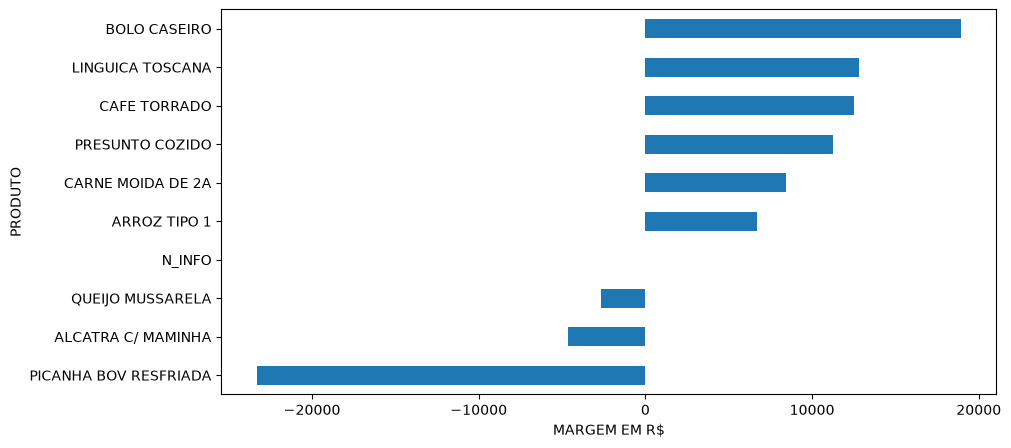

In [68]:
top_10_produtos.plot(
    kind='barh',
    x='NOME_PRODUTO_x',
    y='MARGEM_TOTAL',
    figsize=(10, 5),
    legend=False,
    xlabel='MARGEM EM R$',
    ylabel='PRODUTO'
)

<Axes: title={'center': 'Margem total por categoria (R$)'}, xlabel='CATEGORIA', ylabel='MARGEM TOTAL (R$)'>

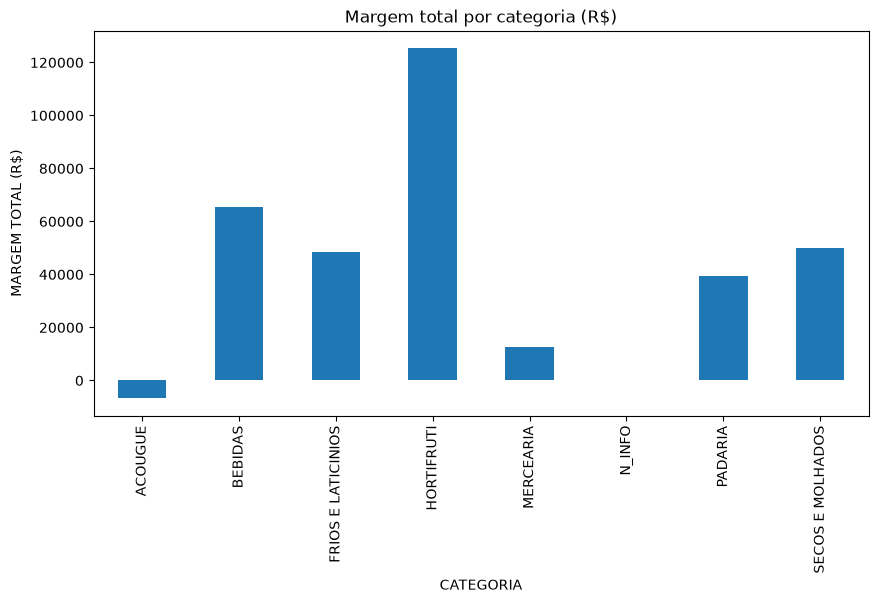

In [69]:
Cons_margem = Vendas_graf.groupby('CATEGORIA_BRUTA', as_index=False)['MARGEM_TOTAL'].sum()

Cons_margem.plot(kind='bar', x='CATEGORIA_BRUTA', y='MARGEM_TOTAL', figsize=(10, 5), legend=False, title='Margem total por categoria (R$)', xlabel='CATEGORIA',
ylabel='MARGEM TOTAL (R$)')

### Cria um grafico para cat x total

<Axes: xlabel='FATURAMENTO R$', ylabel='QTD_VENDIDA'>

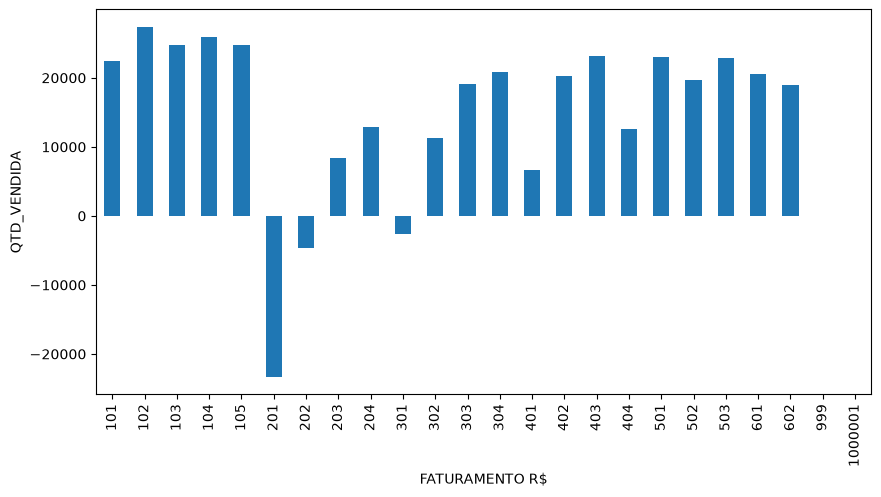

In [108]:
LucroPrejuizo = Vendas_graf.groupby(
    'COD_PRODUTO',
    as_index=False
)['MARGEM_TOTAL'].sum()

LucroPrejuizo.plot(
    kind='bar',
    y='MARGEM_TOTAL',
    x='COD_PRODUTO',
    figsize=(10, 5),
    legend=False,
    xlabel='FATURAMENTO R$',
    ylabel='QTD_VENDIDA',
    
)

<Axes: xlabel='NOME PRODUTO', ylabel='MARGEM'>

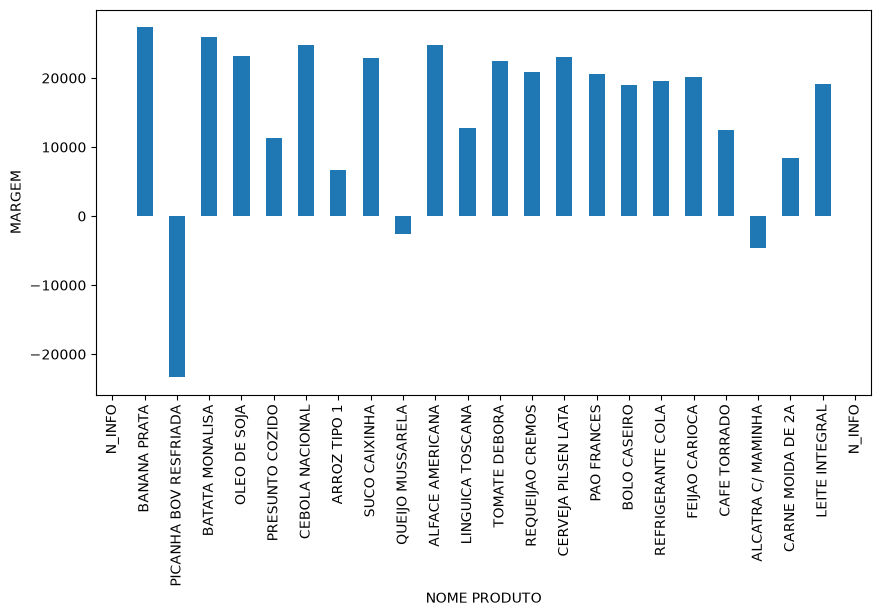

In [109]:
Vendas_graf.plot(
    kind='bar',
    y='MARGEM_TOTAL',
    x='NOME_PRODUTO_x',
    figsize=(10, 5),
    legend=False,
    xlabel='NOME PRODUTO',
    ylabel='MARGEM'
    
)

<Axes: xlabel='CATEGORIA', ylabel='FATURAMENTO R$'>

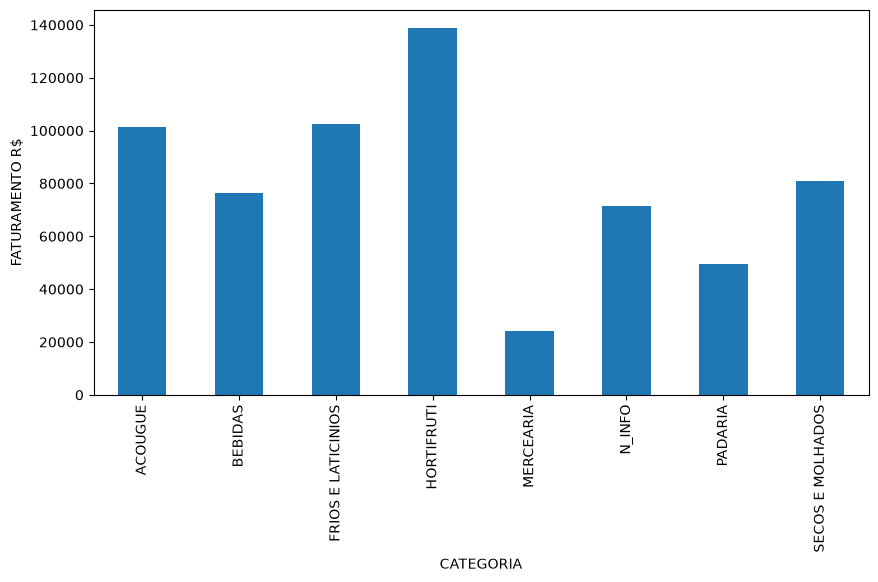

In [110]:
Cons_Unitario = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['FATURAMENTO'].sum()


Cons_Unitario.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='FATURAMENTO',
    figsize=(10, 5),
    legend=False,
    ylabel='FATURAMENTO R$',
    xlabel='CATEGORIA'
)

### Cria um grafico para cat x a média da margem de lucro

<Axes: xlabel='CATEGORIA', ylabel='MEDIA - MARGEM LUCRO - R$'>

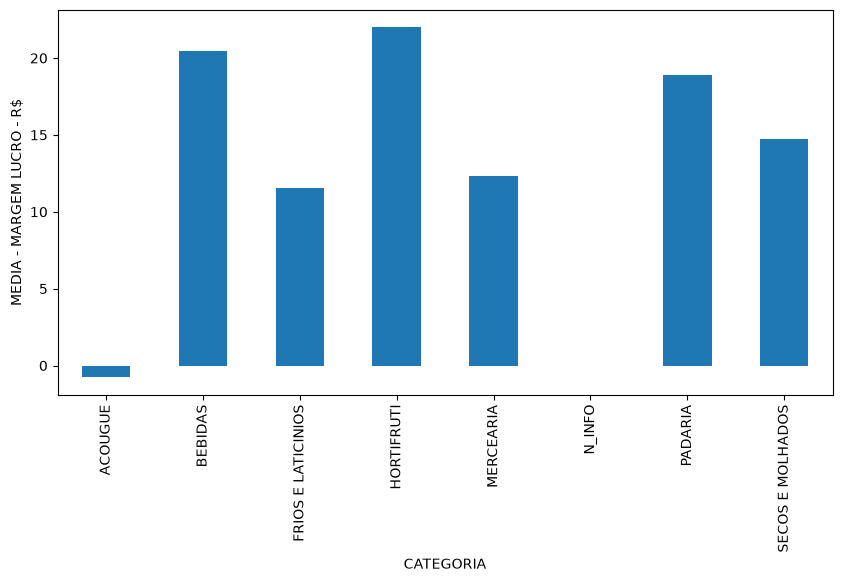

In [111]:
Cons_Unitario_2 = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['V_MARGEM'].mean()


Cons_Unitario_2.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='V_MARGEM',
    figsize=(10, 5),
    legend=False,
    ylabel='MEDIA - MARGEM LUCRO - R$',
    xlabel='CATEGORIA'
)

### Cria um grafico para cat x total

<Axes: xlabel='CATEGORIA', ylabel='SOMA MARGEM LUCRO'>

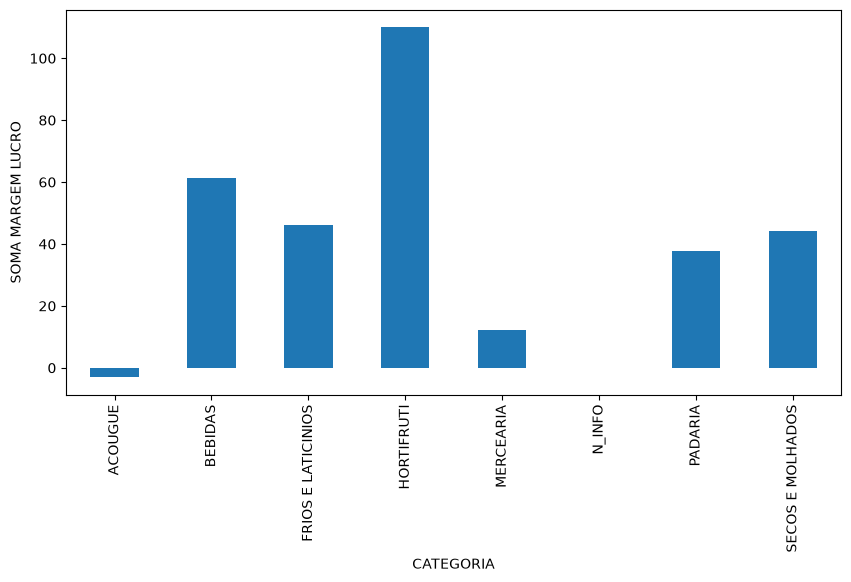

In [112]:
Cons_Unitario_2 = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['V_MARGEM'].sum()


Cons_Unitario_2.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='V_MARGEM',
    figsize=(10, 5),
    legend=False,
    ylabel='SOMA MARGEM LUCRO',
    xlabel='CATEGORIA'
)